<div dir="rtl">

# کارخانه داده درخواست‌های شهری نیویورک

پاسخ مرحلهٔ اول — احسان سویزی

هدف، تولید دادهٔ قابل اتکا در سطح پرونده و جدول ماهانهٔ منطقه و نوع شکایت است. تنظیمات، قرارداد، قرنطینه، اتصال جمعیت، تکرارپذیری و تست‌ها در ادامه بررسی می‌شوند. تحلیل اکتشافی فقط snapshot ذخیره‌شده را توصیف می‌کند.

از پوشهٔ پروژه اجرا کنید. دریافت اولیه را با `python -m data_factory run --stage all` انجام دهید. اجرای این نوت‌بوک، دادهٔ ذخیره‌شده را بدون شبکه بازپردازش می‌کند؛ اگر داده‌ای موجود نباشد دریافت اولیه خودکار شروع می‌شود. برای ادامهٔ یک snapshot ناقص، فرمان `--stage ingest` یا گزینهٔ `DOWNLOAD_REMOTE=True` را به کار ببرید. وضعیت کامل‌بودن دامنه جداگانه نمایش داده می‌شود.

</div>


In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

_start_dir = Path.cwd().resolve()
_root_candidates = [_start_dir, *_start_dir.parents,
                    _start_dir / "machine_learning_challenge"]
PROJECT_ROOT = next((path for path in _root_candidates
                       if (path / "pyproject.toml").is_file()
                       and (path / "config/setting.json").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the notebook within the project or its parent directory.")
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
pd.set_option("display.max_columns", None)
%matplotlib inline


In [2]:
from data_factory.config import load_config
from data_factory.ingestion import build_scope_filter, download_batches, prepare_checkpoint

config = load_config("config/setting.json")
source = config["source"]
http = config["http"]
SEED = source["seed"]
np.random.seed(SEED)
DOWNLOAD_REMOTE = False
print("Seed:", SEED)
display(pd.Series(source, name="selected_scope"))


Seed: 42


endpoint              https://data.cityofnewyork.us/resource/erm2-nw...
start_date                                          2024-01-01T00:00:00
end_date_exclusive                                  2025-07-01T00:00:00
boroughs                                                             []
complaint_types       [Noise - Residential, Noise - Vehicle, Noise -...
minimum_records                                                  300000
seed                                                                 42
Name: selected_scope, dtype: object

In [3]:
scope_filter = build_scope_filter(config)
checkpoint = prepare_checkpoint(config)
minimum_records = source["minimum_records"]
print("Filter:", scope_filter)
print("Saved records:", f"{checkpoint['downloaded_records']:,}")
print("Minimum volume met:", checkpoint["downloaded_records"] >= minimum_records)
print("Full interval acquired:", checkpoint["completed"])
print("No live COUNT query is needed to reproduce saved results.")


Filter: created_date >= '2024-01-01T00:00:00.000000' AND created_date < '2025-07-01T00:00:00.000000' AND complaint_type IN ('Noise - Commercial', 'Noise - Park', 'Noise - Residential', 'Noise - Street/Sidewalk', 'Noise - Vehicle')
Saved records: 330,000
Minimum volume met: True
Full interval acquired: False
No live COUNT query is needed to reproduce saved results.


<div dir="rtl">

## دامنهٔ دریافت و شرط حجم

پنج نوع شکایت سر‌وصدا در فاصلهٔ ابتدای ژانویهٔ ۲۰۲۴ تا ابتدای ژوئیهٔ ۲۰۲۵ انتخاب شده‌اند. همهٔ boroughها حفظ شده‌اند. حداقل ۳۰۰هزار رکورد شرط حجم است و جایگزین پوشش کامل بازه نیست؛ تعداد فعلی از checkpoint خوانده می‌شود. برای بازتولید، پرس‌وجوی شمارش از منبع زنده انجام نمی‌شود.

</div>


<div dir="rtl" style="text-align: right; line-height: 2;">

**آماده‌سازی checkpoint**

سلول بعد، بدون درخواست به API، وضعیت موجود را بررسی می‌کند و در صورت نبودن آن، فایل `data/raw_data/checkpoint.json` را می‌سازد. این فایل شمارهٔ آخرین batch، تعداد رکوردهای ذخیره‌شده، آخرین `created_date` و `unique_key`، مشخصات فیلتر و هش فایل‌ها را نگه می‌دارد. آن را دستی ویرایش نکنید.

رکوردها بر اساس `created_date ASC, unique_key ASC` مرتب می‌شوند. شرط درخواست بعدی از هر دو مقدار استفاده می‌کند تا رکوردهای هم‌زمان جا نیفتند؛ `unique_key` رشته باقی می‌ماند.

</div>


In [4]:
checkpoint = prepare_checkpoint(config)
checkpoint_path = Path(config["paths"]["raw_dir"]) / config["paths"]["checkpoint_file"]
print("Checkpoint:", checkpoint_path.as_posix())
display(pd.Series({key: checkpoint[key] for key in (
    "last_batch", "downloaded_records", "last_created_date", "last_unique_key", "completed"
)}, name="acquisition_state"))


Checkpoint: data/raw_data/checkpoint.json


last_batch                                 66
downloaded_records                     330000
last_created_date     2024-07-25T23:32:51.000
last_unique_key                      61923228
completed                               False
Name: acquisition_state, dtype: object

<div dir="rtl">

## دریافت و ادامه پس از وقفه

دریافت با ترتیب زمان ایجاد و شناسه پیش می‌رود و تنها پاسخ خالی آن را کامل می‌کند. فایل خام پیش از checkpoint ذخیره می‌شود؛ فایل باقی‌مانده پس از وقفه بازیابی می‌شود. `DOWNLOAD_REMOTE=True` تمام batchهای باقی‌مانده را می‌گیرد. حالت پیش‌فرض، snapshot موجود را برای اجرای آفلاین حفظ می‌کند.

</div>


In [5]:
# An empty project acquires its scope; saved snapshots are replayed offline by default.
if DOWNLOAD_REMOTE or checkpoint["downloaded_records"] == 0:
    download_summary = download_batches(config)
else:
    download_summary = checkpoint
print("Downloaded records:", f"{download_summary['downloaded_records']:,}")
print("Saved batches:", download_summary["last_batch"])
print("Completed:", download_summary["completed"])


Downloaded records: 330,000
Saved batches: 66
Completed: False


In [6]:
# Read the persisted state, including after an interrupted download.
checkpoint = prepare_checkpoint(config)
print("Saved records:", f"{checkpoint['downloaded_records']:,}")
print("Saved batches:", checkpoint["last_batch"])
print("Completed:", checkpoint["completed"])

if checkpoint["last_batch"]:
    # Preview one saved batch, never concatenate the entire raw dataset.
    first_batch_path = Path(config["paths"]["raw_dir"]) / "batch_000001.json"
    with first_batch_path.open(encoding="utf-8") as file:
        first_batch = json.load(file)
    display(pd.DataFrame(first_batch[:5]))
    del first_batch


Saved records: 330,000
Saved batches: 66
Completed: False


,address_type,agency,agency_name,bbl,borough,city,closed_date,community_board,complaint_type,council_district,created_date,cross_street_1,cross_street_2,descriptor,incident_address,incident_zip,intersection_street_1,intersection_street_2,landmark,latitude,location,location_type,longitude,open_data_channel_type,park_borough,park_facility_name,police_precinct,resolution_action_updated_date,resolution_description,status,street_name,unique_key,x_coordinate_state_plane,y_coordinate_state_plane
0,ADDRESS,NYPD,New York City Police Department,2032367501,BRONX,BRONX,2024-01-01T00:59:31.000,07 BRONX,Noise - Residential,14,2024-01-01T00:00:20.000,CEDAR AVENUE,MAJOR DEEGAN EXPRESSWAY,Loud Music/Party,233 LANDING ROAD,10468,CEDAR AVENUE,MAJOR DEEGAN EXPRESSWAY,LANDING ROAD,40.86240645467484,"{'coordinates': [-73.911097148279, 40.86240645...",Residential Building/House,-73.91109714827905,PHONE,BRONX,Unspecified,Precinct 52,2024-01-01T00:59:34.000,The Police Department responded to the complai...,Closed,LANDING ROAD,59889016,1008841,253488
1,ADDRESS,NYPD,New York City Police Department,3043710001,BROOKLYN,BROOKLYN,2024-01-01T00:56:45.000,05 BROOKLYN,Noise - Residential,42,2024-01-01T00:00:43.000,VERMONT STREET,VAN SICLEN AVENUE,Banging/Pounding,640 STANLEY AVENUE,11207,VERMONT STREET,VAN SICLEN AVENUE,STANLEY AVENUE,40.65893182677183,"{'coordinates': [-73.884862783149, 40.65893182...",Residential Building/House,-73.88486278314905,MOBILE,BROOKLYN,Unspecified,Precinct 75,2024-01-01T00:56:50.000,The Police Department responded to the complai...,Closed,STANLEY AVENUE,59888940,1016195,179364
2,ADDRESS,NYPD,New York City Police Department,4013110066,QUEENS,WOODSIDE,2024-01-01T00:48:34.000,02 QUEENS,Noise - Street/Sidewalk,26,2024-01-01T00:00:48.000,41 AVENUE,WOODSIDE AVENUE,Loud Music/Party,41-52 72 STREET,11377,41 AVENUE,WOODSIDE AVENUE,72 STREET,40.74376141146886,"{'coordinates': [-73.893186092905, 40.74376141...",Street/Sidewalk,-73.8931860929054,ONLINE,QUEENS,Unspecified,Precinct 108,2024-01-01T00:48:39.000,The Police Department responded to the complai...,Closed,72 STREET,59892651,1013848,210267
3,ADDRESS,NYPD,New York City Police Department,4090210002,QUEENS,OZONE PARK,2024-01-01T00:29:32.000,09 QUEENS,Noise - Street/Sidewalk,32,2024-01-01T00:00:51.000,85 STREET,86 STREET,Loud Music/Party,85-04 95 AVENUE,11416,85 STREET,86 STREET,95 AVENUE,40.68473836098068,"{'coordinates': [-73.855753236702, 40.68473836...",Street/Sidewalk,-73.85575323670186,MOBILE,QUEENS,Unspecified,Precinct 102,2024-01-01T00:29:34.000,The Police Department responded to the complai...,Closed,95 AVENUE,59889054,1024256,188778
4,ADDRESS,NYPD,New York City Police Department,4150010087,QUEENS,JAMAICA,2024-01-01T01:32:22.000,13 QUEENS,Noise - Street/Sidewalk,31,2024-01-01T00:01:01.000,SOUTH CONDUIT AVENUE,146 AVENUE,Loud Music/Party,144-25 153 LANE,11434,SOUTH CONDUIT AVENUE,146 AVENUE,153 LANE,40.66610329232783,"{'coordinates': [-73.78495540739, 40.666103292...",Street/Sidewalk,-73.78495540739017,MOBILE,QUEENS,Unspecified,Precinct 105,2024-01-01T01:32:26.000,The Police Department responded to the complai...,Closed,153 LANE,59892073,1043908,182029


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>گام اول: بررسی کیفیت دادهٔ خام</strong></p>
<p>این مرحله روی فایل‌های خام موجود اجرا می‌شود و درخواست شبکه‌ای ندارد. تعداد batchهای بررسی‌شده از <code>validation.inspection_batches</code> در فایل تنظیمات خوانده می‌شود. batchها با فاصلهٔ تقریباً مساوی، از اولین تا آخرین batch ذخیره‌شده انتخاب می‌شوند. این انتخاب برای شناخت داده است و دامنهٔ دانلود یا فایل‌های خام را تغییر نمی‌دهد.</p>
<p>گزارش در <code>data/curated_data/raw_inspection.json</code> ذخیره می‌شود. در جدول، مقدار خالی شامل کلید غایب، مقدار JSON null یا رشتهٔ خالی/فقط فاصله است. عبارت‌هایی مثل <code>Unspecified</code> جداگانه شمرده می‌شوند و فعلاً سیاست پاک‌سازی روی آن‌ها اعمال نمی‌شود.</p>
<p>دامنهٔ این گزارش فقط batchهای انتخاب‌شده است. اگر <code>snapshot_completed</code> برابر false باشد، دریافت کل بازهٔ ۱۸ماهه هنوز تکمیل نشده است. سلول‌های این گام مستقل از سلول دانلود قابل اجرا هستند.</p>
</div>


In [7]:
from pathlib import Path

import pandas as pd
from IPython.display import display

from data_factory.config import load_config
from data_factory.quality import inspect_raw_data

# Run independently, without executing the acquisition/count cells.
_start_dir = Path.cwd().resolve()
_root_candidates = [_start_dir, *_start_dir.parents,
                    _start_dir / "machine_learning_challenge"]
inspection_root = next((path for path in _root_candidates
                       if (path / "pyproject.toml").is_file()
                       and (path / "config/setting.json").is_file()), None)
if inspection_root is None:
    raise FileNotFoundError("Open the notebook within the project or its parent directory.")

inspection_config = load_config(inspection_root / "config/setting.json")
for path_key in ("raw_dir", "curated_dir"):
    inspection_config["paths"][path_key] = str(
        inspection_root / inspection_config["paths"][path_key]
    )

inspection_report = inspect_raw_data(inspection_config)
print("Available snapshot records:", f"{inspection_report['snapshot_records']:,}")
print("Inspected records:", f"{inspection_report['selected_records']:,}")
print("Full acquisition completed:", inspection_report["snapshot_completed"])
print("Observed source columns:", len(inspection_report["profile"]["columns"]))
print("Selected batches:", ", ".join(inspection_report["selected_files"]))

inspection_table = pd.DataFrame([
    {
        "field": name,
        "absent_keys": stats["absent_key_count"],
        "explicit_nulls": stats["null_count"],
        "blank_strings": stats["blank_count"],
        "missing_count": stats["missing_count"],
        "missing_percent": stats["missing_percent"],
        "unique_non_missing": stats["unique_non_missing"],
        "raw_json_types": ", ".join(sorted(stats["json_types"])),
        "sentinel_counts": stats["sentinel_counts"],
    }
    for name, stats in inspection_report["profile"]["columns"].items()
])
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(inspection_table)


Inspected 30,000 records from 6 batches; report: D:\ehsan\work\dotin\term_three\challenges\ML\challenge_one\machine_learning_challenge\data\curated_data\raw_inspection.json
Available snapshot records: 330,000
Inspected records: 30,000
Full acquisition completed: False
Observed source columns: 35
Selected batches: batch_000001.json, batch_000014.json, batch_000027.json, batch_000040.json, batch_000053.json, batch_000066.json


,field,absent_keys,explicit_nulls,blank_strings,missing_count,missing_percent,unique_non_missing,raw_json_types,sentinel_counts
0,address_type,3,0,0,3,0.010000,4,string,{}
1,agency,0,0,0,0,0.000000,1,string,{}
2,agency_name,0,0,0,0,0.000000,1,string,{}
3,bbl,2199,0,0,2199,7.330000,11886,string,{}
4,borough,0,0,0,0,0.000000,5,string,{}
5,city,1391,0,0,1391,4.636667,46,string,{}
6,closed_date,0,0,0,0,0.000000,29537,string,{}
7,community_board,0,0,0,0,0.000000,73,string,{}
8,complaint_type,0,0,0,0,0.000000,5,string,{}
9,council_district,170,0,0,170,0.566667,51,string,{}


In [8]:
print("Date observations (no records removed):")
display(pd.Series(inspection_report["date_observations"], name="record_count"))

for category_field in ("status", "open_data_channel_type"):
    category_summary = inspection_report["categorical_counts"].get(category_field)
    if category_summary is not None:
        print("Observed values:", category_field)
        display(pd.DataFrame(category_summary["values"]))
        print("Values beyond the configured category limit:", category_summary["other_count"])

inspection_report_path = (
    Path(inspection_config["paths"]["curated_dir"])
    / inspection_config["paths"]["inspection_file"]
)
print("Saved report:", inspection_report_path.relative_to(inspection_root))


Date observations (no records removed):


closed_date_missing           0
closed_date_unparseable       0
created_date_missing          0
created_date_unparseable      0
incomparable_closure_dates    0
negative_closure_intervals    0
Name: record_count, dtype: int64

Observed values: status


,value,count
0,Closed,29998
1,Unspecified,2


Values beyond the configured category limit: 0
Observed values: open_data_channel_type


,value,count
0,ONLINE,15796
1,MOBILE,8338
2,PHONE,5862
3,OTHER,2
4,UNKNOWN,2


Values beyond the configured category limit: 0
Saved report: data\curated_data\raw_inspection.json


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>تفسیر خروجی گام اول</strong></p>
<ul>
<li>جدول ستون‌ها وضعیت دادهٔ خام را نشان می‌دهد؛ برای مثال کد پستی به‌صورت رشته باقی مانده و رشته‌های عددی به عدد تبدیل نشده‌اند. دامنهٔ رشته‌ها در گزارش JSON بر اساس ترتیب متنی است.</li>
<li>کمبود کد پستی یا مختصات را از نبود شناسه یا تاریخ ثبت جدا بررسی می‌کنیم. تصمیم نهایی دربارهٔ مقدار خالی، اصلاح یا قرنطینه در گام قرارداد داده ثبت می‌شود.</li>
<li><code>UNKNOWN</code> در کانال ثبت درخواست یک مقدار مشاهده‌شده است و با null تفاوت دارد. شمردن عبارت‌های قراردادی در این مرحله به معنی حذف یا تبدیل آن‌ها نیست.</li>
<li>بررسی تاریخ‌ها تعداد مقادیر خالی، غیرقابل‌تفسیر و فاصلهٔ بسته‌شدن منفی را نشان می‌دهد. پیدا نشدن یک خطا در این نمونه، نبود آن در تمام داده‌ها را اثبات نمی‌کند.</li>
<li>گزارش این مرحله با اجرای دوباره روی همان snapshot و تنظیمات، محتوای یکسان تولید می‌کند. هیچ رکوردی در این گام اصلاح، حذف یا قرنطینه نمی‌شود.</li>
</ul>
<p>گام اول در همین نقطه پایان می‌یابد. تعریف و نهایی‌سازی قواعد schema و قرنطینه، گام بعدی است.</p>
</div>


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>گام دوم: تعریف قرارداد داده</strong></p>
<p>قرارداد نسخهٔ ۱ در <code>config/schema.json</code> مشخص می‌کند هر ستونِ خروجی چه نقشی دارد، نوع منطقی آن چیست، آیا مقدار خالی مجاز است و با مقدار نامعتبر چه می‌کنیم. این یک قرارداد اختصاصی پروژه است و از استاندارد عمومی JSON Schema استفاده نمی‌کند.</p>
<p>برای تحلیل مدت بسته‌شدن، روند ماهانه و اتصال جمعیت، ۱۷ ستون منبع انتخاب شده‌اند. چهار ستون مشتق‌شده هم تعریف می‌شوند. فیلدهای دیگر منبع در فایل خام کامل باقی می‌مانند؛ نمایش این قرارداد هنوز هیچ ستونی را از داده حذف نمی‌کند.</p>
<p><code>source_types</code> نوع مشاهده‌شده در JSON خام است؛ <code>target_type</code> نوع منطقی پس از تبدیل است. مثلاً مختصات در منبع رشته‌اند ولی نوع هدف آن‌ها عدد اعشاری است. تاریخ‌ها در JSONL آینده به‌صورت رشتهٔ ISO ذخیره می‌شوند، چون JSON نوع تاریخ بومی ندارد.</p>
<p><code>nullable</code> دربارهٔ خالی‌بودن مقدار در یک رکورد است. <code>required_presence</code> به کنترل ساختار یک batch مربوط است؛ برای ستون‌های اختیاری، غیبت کلید به‌تنهایی نشانهٔ حذف ستون از API نیست. مقدارهای مجاز نوع شکایت از تنظیمات خوانده می‌شوند و اینجا دوباره hard-code نشده‌اند.</p>
<p>سلول‌های این گام فقط خودِ قرارداد را بررسی و نمایش می‌دهند؛ رکوردها را اعتبارسنجی یا قرنطینه نمی‌کنند.</p>
</div>


In [9]:
from pathlib import Path

import pandas as pd
from IPython.display import display

from data_factory.config import load_config
from data_factory.schema import contract_rows, load_schema

_start_dir = Path.cwd().resolve()
_root_candidates = [_start_dir, *_start_dir.parents,
                    _start_dir / "machine_learning_challenge"]
contract_root = next((path for path in _root_candidates
                       if (path / "pyproject.toml").is_file()
                       and (path / "config/setting.json").is_file()), None)
if contract_root is None:
    raise FileNotFoundError("Open the notebook within the project or its parent directory.")

contract_config = load_config(contract_root / "config/setting.json")
contract_path = contract_root / contract_config["validation"]["schema_path"]
data_contract = load_schema(contract_path, source=contract_config["source"])
contract_table = pd.DataFrame(
    contract_rows(data_contract, source=contract_config["source"])
)

print("Contract:", contract_path.relative_to(contract_root))
print("Version:", data_contract["version"])
print("Declared source fields:", len(data_contract["fields"]))
print("Declared derived fields:", len(data_contract["derived_fields"]))
print("Contract configuration valid; no source records were processed.")

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(contract_table[[
        "field", "source_types", "target_type", "nullable",
        "required_presence", "on_invalid",
    ]])
    display(contract_table[[
        "field", "allowed", "pattern", "min", "max", "missing_tokens",
    ]])


Contract: config\schema.json
Version: 1
Declared source fields: 17
Declared derived fields: 4
Contract configuration valid; no source records were processed.


,field,source_types,target_type,nullable,required_presence,on_invalid
0,unique_key,[string],string,False,True,quarantine
1,created_date,[string],datetime,False,True,quarantine
2,closed_date,[string],datetime,True,False,quarantine
3,agency,[string],string,False,True,quarantine
4,agency_name,[string],string,True,False,set_null
5,complaint_type,[string],string,False,True,quarantine
6,descriptor,[string],string,True,False,set_null
7,status,[string],string,True,False,set_null
8,incident_zip,[string],string,True,False,set_null
9,borough,[string],string,True,False,set_null


,field,allowed,pattern,min,max,missing_tokens
0,unique_key,None,^[0-9]+$,NaN,NaN,[]
1,created_date,None,None,NaN,NaN,[]
2,closed_date,None,None,NaN,NaN,"[, N/A, Unspecified]"
3,agency,None,None,NaN,NaN,"[, N/A, Unspecified, UNKNOWN]"
4,agency_name,None,None,NaN,NaN,"[, N/A, Unspecified]"
5,complaint_type,"[Noise - Residential, Noise - Vehicle, Noise -...",None,NaN,NaN,[]
6,descriptor,None,None,NaN,NaN,"[, N/A, Unspecified]"
7,status,None,None,NaN,NaN,"[, N/A, Unspecified, UNKNOWN]"
8,incident_zip,None,^[0-9]{5}$,NaN,NaN,"[, N/A, 00000, Unspecified, UNKNOWN]"
9,borough,"[BRONX, BROOKLYN, MANHATTAN, QUEENS, STATEN IS...",None,NaN,NaN,"[, N/A, Unspecified, UNKNOWN]"


In [10]:
print("Purpose and per-field missing/invalid-value decisions:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
    display(contract_table[[
        "field", "description", "missing_policy", "invalid_policy_reason",
    ]])

derived_contract_table = pd.DataFrame([
    {"field": name, **rule}
    for name, rule in data_contract["derived_fields"].items()
])
print("Derived fields (definitions only):")
with pd.option_context("display.max_colwidth", None):
    display(derived_contract_table)


Purpose and per-field missing/invalid-value decisions:


,field,description,missing_policy,invalid_policy_reason
0,unique_key,Service-request identifier and dataset-wide primary key; keep as text.,Missing identifiers quarantine the record; never generate replacement IDs.,A stable nonempty identifier is necessary for deduplication and provenance.
1,created_date,Recorded creation timestamp; defines the selected scope and created_month.,Missing creation dates quarantine the record; never impute them.,An invalid creation date prevents scope checks and closure-duration calculation.
2,closed_date,"Recorded administrative closure timestamp, possibly absent.","Keep missing dates null; derived closure_hours stays null, never zero.",A malformed nonmissing closure date cannot be used as a trustworthy outcome.
3,agency,"Responsible agency code; trim and normalize case, without an NYPD-only filter.",Missing agency codes quarantine the record; do not infer them from the sample.,Responsibility is a core analytical dimension; the sample is not a global domain list.
4,agency_name,Optional readable label for the responsible agency.,Keep null and flag the missing value; do not copy or guess an agency name.,The agency code remains usable when its descriptive label is invalid.
5,complaint_type,Problem category; permitted values come from source.complaint_types in settings.,Missing categories quarantine the record; no category imputation.,Missing or out-of-scope categories prevent the intended complaint comparison.
6,descriptor,Optional problem detail within the complaint category.,Keep null and flag missing detail; retain the service request.,Complaint type and dates remain useful without the optional problem detail.
7,status,Reported workflow status; preserve known and new nonmissing labels.,Treat configured sentinels such as Unspecified as null with a flag.,Unknown status alone does not invalidate a usable recorded closure date.
8,incident_zip,Five-digit ZIP text used for a future population join; leading zeros are preserved.,"Null, blank and configured placeholders remain null with a visible flag.",An unusable ZIP becomes null with a flag; retain the case for non-ZIP analyses.
9,borough,Reported borough; normalize to the five listed NYC borough names when usable.,Keep unknown borough null with a flag; do not infer it from ZIP in this stage.,An unusable borough becomes null with a flag; a configured borough scope remains a hard rule.


Derived fields (definitions only):

,field,type,nullable,description
0,created_month,string,False,YYYY-MM from the floating created_date; no timezone conversion.
1,closure_hours,float,True,"Difference of recorded floating closed_date and created_date in hours; null when closure is missing, zero is valid, no timezone conversion."
2,has_recorded_closure,boolean,False,Whether a usable closed_date is present; does not prove the issue was resolved.
3,quality_flags,array,False,Sorted warning codes for optional fields and status/date inconsistencies.


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>قواعد بین ستون‌ها و دلیل تصمیم‌ها</strong></p>
<ul>
<li><code>unique_key</code> شناسهٔ متنی و یکتا در کل رکوردهای پذیرفته‌شده است. شکایت‌های مشابه با شناسه‌های متفاوت، خودکار تکراری محسوب نمی‌شوند.</li>
<li>برای تکرار یک شناسه، سیاست مرحلهٔ بعد نگه‌داشتن اولین رخداد معتبر در ترتیب فایل‌هاست. تکرار کامل خام با <code>DUPLICATE_RECORD</code> و محتوای خام متفاوت با همان شناسه با <code>DUPLICATE_KEY_CONFLICT</code> ثبت می‌شود. این انتخاب قطعی است و ادعای انتخاب جدیدترین نسخه را ندارد.</li>
<li>تاریخ ثبت باید داخل بازهٔ تنظیمات باشد: شروع شامل و پایان غیرشامل است. نوع شکایت و فیلتر اختیاری منطقه از تنظیمات می‌آیند. تاریخ بسته‌شدن می‌تواند بعد از انتهای این بازه باشد.</li>
<li>تاریخ ثبت یا شناسهٔ نامعتبر، نبود آژانس مسئول و نوع شکایت نامعتبر قواعد سخت دارند. متن آژانس به NYPD محدود نمی‌شود، حتی اگر تمام نمونهٔ بررسی‌شده NYPD باشد.</li>
<li>تاریخ بسته‌شدن خالی حفظ می‌شود؛ مدت بسته‌شدن هم خالی خواهد بود. مقدار صفر فقط وقتی معتبر است که دو تاریخ برابر باشند. فاصلهٔ منفی به قرنطینه می‌رود؛ برای فاصله‌های مثبت طولانی، سقف دلخواه تعیین نمی‌کنیم.</li>
<li>مدت بسته‌شدن از اختلاف زمان‌های ثبت‌شدهٔ بدون offset محاسبه می‌شود؛ تبدیل خودکار به UTC یا اصلاح منطقهٔ زمانی انجام نمی‌دهیم. این معیار بسته‌شدن اداری پرونده است.</li>
<li>مقادیر خالی یا نامعتبرِ قابل‌اصلاح در اطلاعات مکانی و توصیفی، با null و پرچم کیفیت ثبت می‌شوند. این تصمیم برای حفظ قابلیت تحلیل پرونده در ابعادی است که به آن مقدار نیاز ندارند. مقدار خام در فایل اصلی محفوظ می‌ماند.</li>
<li>کد پستی رشتهٔ پنج‌رقمی است و صفر ابتدایی حفظ می‌شود. این الگو فقط شکل مقدار را کنترل می‌کند؛ وجود واقعی ZIP و پوشش مرجع جمعیت در مرحلهٔ اتصال بررسی خواهد شد.</li>
<li>مختصات باید عدد متناهی و داخل حدود جهانی مجاز باشند؛ این شرط به‌تنهایی ثابت نمی‌کند نقطه داخل نیویورک است. اگر فقط یکی از دو مختصات قابل‌استفاده باشد، هر دو با پرچم مناسب خالی می‌شوند.</li>
<li><code>Unspecified</code> در وضعیت، مقدار خالیِ علامت‌گذاری‌شده خواهد شد؛ اما <code>UNKNOWN</code> در کانال ثبت یک دستهٔ قابل‌نگهداری است. برای دسته‌های جدید کانال یا وضعیت، فقط بر اساس فهرست کوچک نمونه رکورد را رد نمی‌کنیم.</li>
<li>ناسازگاری وضعیت با تاریخ بسته‌شدن علامت‌گذاری می‌شود؛ از روی وضعیت، تاریخ نمی‌سازیم. وجود توضیح رسیدگی هم به معنی اثبات حل واقعی مشکل نیست.</li>
</ul>
<p>جدول‌ها در این گام قرارداد را تعریف می‌کنند. اجرای این قواعد روی رکوردها، شمارش پذیرش/قرنطینه و تولید دادهٔ پردازش‌شده مربوط به گام بعد است. گزارش بررسی گام اول و checkpoint در این گام تغییر نمی‌کنند.</p>
</div>


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>گام سوم: اجرای قرارداد داده و قرنطینه</strong></p>
<p>در این مرحله قرارداد گام دوم روی تمام batchهای ثبت‌شده در checkpoint اجرا می‌شود. داده‌ها به‌صورت batch به batch خوانده می‌شوند؛ برای تشخیص تکرار در کل داده و شمارش مقادیر یکتا از SQLite موقت روی دیسک استفاده می‌شود. هیچ درخواست شبکه‌ای لازم نیست و فایل‌های خام بازنویسی نمی‌شوند.</p>
<p>مقادیر معتبر تبدیل نوع می‌شوند و چهار ستون مشتق‌شده ساخته می‌شود. خطای اساسی مثل نبود شناسه، تاریخ نامعتبر، بسته‌شدن پیش از ثبت یا خروج از دامنه، رکورد را همراه اصل داده، نام فایل، شماره سطر و کد دلیل به قرنطینه می‌فرستد. اشکال ستون اختیاری طبق قرارداد با null و پرچم کیفیت ثبت می‌شود. اولین رخداد معتبر هر شناسه حفظ و تکرارهای بعدی، حتی در batch دیگر، قرنطینه می‌شوند.</p>
<p>آستانهٔ فعلی <code>validation.max_quarantine_fraction = 0.01</code> است: بیش از یک درصد خطای اساسی، اجرای مرحله را شکست می‌دهد تا پیش از ادامه، علت بررسی شود. این آستانه یک کنترل عملیاتی قابل‌تنظیم است، نه تضمین آماری کیفیت؛ هشدارهای مربوط به مقادیر اختیاری جداگانه گزارش می‌شوند. در شکستِ آستانه، خروجی تشخیصی ابتدا ذخیره می‌شود؛ در تغییر ساختاری منبع، مرحله بدون انتشار نتیجهٔ ناقص متوقف می‌شود.</p>
<p>این بخش مستقل از سلول‌های شمارش و دانلود قابل اجراست. قبولی اعتبارسنجی روی دریافت ناقص، به معنی تکمیل بازهٔ ۱۸ماهه نیست؛ وضعیت واقعی در خروجی نمایش داده می‌شود.</p>
</div>

In [11]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display

from data_factory.config import load_config
from data_factory.exceptions import QuarantineThresholdError
from data_factory.quality import validate_dataset

# This section runs independently of the network/acquisition cells.
_start_dir = Path.cwd().resolve()
_root_candidates = [_start_dir, *_start_dir.parents,
                    _start_dir / "machine_learning_challenge"]
validation_root = next((path for path in _root_candidates
                       if (path / "pyproject.toml").is_file()
                       and (path / "config/setting.json").is_file()), None)
if validation_root is None:
    raise FileNotFoundError("Open the notebook within the project or its parent directory.")
validation_root = validation_root.resolve()
validation_config = load_config(validation_root / "config/setting.json")
for path_key in ("raw_dir", "curated_dir"):
    validation_config["paths"][path_key] = str(
        validation_root / validation_config["paths"][path_key]
    )
validation_config["validation"]["schema_path"] = str(
    validation_root / validation_config["validation"]["schema_path"]
)

try:
    validation_report = validate_dataset(validation_config)
except QuarantineThresholdError as error:
    failed_report = json.loads(Path(error.report_path).read_text(encoding="utf-8"))
    print("FAILED: diagnostic outputs were saved at", error.report_path)
    print("Quarantine fraction:", failed_report["quarantine_fraction"])
    display(pd.Series(failed_report["reason_counts"], name="rejected_records"))
    raise  # Stop this stage; never treat failed outputs as approved input.

validation_output = Path(validation_report["output_dir"])
print("Status:", validation_report["status"])
print("Full acquisition completed:", validation_report["snapshot_completed"])
print("Scope:", validation_report["scope_note"])
print("Outputs:", validation_output.relative_to(validation_root))
display(pd.Series({
    "input_batches": validation_report["input_batches"],
    "raw_records": validation_report["raw_records"],
    "accepted_records": validation_report["accepted_records"],
    "quarantined_records": validation_report["quarantined_records"],
    "quarantine_percent": round(100 * validation_report["quarantine_fraction"], 6),
    "maximum_quarantine_percent": 100 * validation_report["max_quarantine_fraction"],
}, name="validation_summary"))

Validated batch_000001.json: accepted=5,000, quarantined=0


Validated batch_000002.json: accepted=10,000, quarantined=0


Validated batch_000003.json: accepted=15,000, quarantined=0


Validated batch_000004.json: accepted=20,000, quarantined=0


Validated batch_000005.json: accepted=25,000, quarantined=0


...

Validated batch_000064.json: accepted=320,000, quarantined=0


Validated batch_000065.json: accepted=325,000, quarantined=0


Validated batch_000066.json: accepted=330,000, quarantined=0


Status: passed
Full acquisition completed: False
Scope: Partial acquisition; the full selected 18-month scope is not yet available.
Outputs: data\curated_data\validation\c80e394405a584a04f4d6834d5b558d6182991feb18b5f78d69d3ec101abe6b1


input_batches                     66.0
raw_records                   330000.0
accepted_records              330000.0
quarantined_records                0.0
quarantine_percent                 0.0
maximum_quarantine_percent         1.0
Name: validation_summary, dtype: float64

In [12]:
print("Quarantined records per reason (a record may have multiple reasons):")
reason_table = pd.DataFrame([
    {"reason_code": code, "record_count": count}
    for code, count in validation_report["reason_counts"].items()
], columns=["reason_code", "record_count"])
display(reason_table)

print("Quality flags on accepted records (not quarantine reasons):")
warning_table = pd.DataFrame([
    {"quality_flag": code, "record_count": count}
    for code, count in validation_report["warning_counts"].items()
], columns=["quality_flag", "record_count"])
with pd.option_context("display.max_rows", None):
    display(warning_table)

accepted_profile = json.loads(
    (validation_output / "quality_profile.json").read_text(encoding="utf-8")
)
print("Column profile of accepted records only:")
accepted_profile_table = pd.DataFrame([
    {"field": name, "missing_count": stats["missing_count"],
     "missing_percent": stats["missing_percent"],
     "unique_non_missing": stats["unique_non_missing"],
     "json_types": stats["json_types"], "ranges_by_type": stats["ranges_by_type"]}
    for name, stats in accepted_profile["columns"].items()
])
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(accepted_profile_table)

Quarantined records per reason (a record may have multiple reasons):


,reason_code,record_count


Quality flags on accepted records (not quarantine reasons):


,quality_flag,record_count
0,borough:MISSING_VALUE,13
1,city:MISSING_VALUE,14418
2,closed_date:MISSING_VALUE,1
3,incident_zip:MISSING_VALUE,67
4,latitude:MISSING_VALUE,1633
5,longitude:MISSING_VALUE,1633
6,resolution_action_updated_date:MISSING_VALUE,1
7,resolution_description:MISSING_VALUE,13
8,status:MISSING_VALUE,13


Column profile of accepted records only:


,field,missing_count,missing_percent,unique_non_missing,json_types,ranges_by_type
0,agency,0,0.000000,2,{'string': 330000},"{'string': {'max': 'NYPD', 'min': '3-1-1'}}"
1,agency_name,0,0.000000,2,{'string': 330000},{'string': {'max': 'New York City Police Depar...
2,borough,13,0.003939,5,"{'null': 13, 'string': 329987}","{'string': {'max': 'STATEN ISLAND', 'min': 'BR..."
3,city,14418,4.369091,49,"{'null': 14418, 'string': 315582}","{'string': {'max': 'WOODSIDE', 'min': 'ARVERNE'}}"
4,closed_date,1,0.000303,321312,"{'null': 1, 'string': 329999}",{'string': {'max': '2024-07-26T22:13:46.000000...
5,closure_hours,1,0.000303,26857,"{'null': 1, 'number': 329999}","{'number': {'max': 807.6661111111111, 'min': 0..."
6,complaint_type,0,0.000000,5,{'string': 330000},"{'string': {'max': 'Noise - Vehicle', 'min': '..."
7,created_date,0,0.000000,323341,{'string': 330000},{'string': {'max': '2024-07-25T23:32:51.000000...
8,created_month,0,0.000000,7,{'string': 330000},"{'string': {'max': '2024-07', 'min': '2024-01'}}"
9,descriptor,0,0.000000,7,{'string': 330000},"{'string': {'max': 'Loud Television', 'min': '..."


In [13]:
from itertools import islice
import hashlib

# Read at most five lines from either output; never load the whole dataset.
for output_name in ("accepted.jsonl", "quarantine.jsonl"):
    with (validation_output / output_name).open(encoding="utf-8") as file:
        preview = [json.loads(line) for line in islice(file, 5)]
    print(output_name, "(up to five rows):")
    if preview:
        display(pd.DataFrame(preview))
    else:
        print("No records.")

assert validation_report["raw_records"] == (
    validation_report["accepted_records"] + validation_report["quarantined_records"]
)
assert accepted_profile["rows"] == validation_report["accepted_records"]
assert accepted_profile["columns"]["unique_key"]["unique_non_missing"] == accepted_profile["rows"]
for output_name, metadata in validation_report["files"].items():
    with (validation_output / output_name).open("rb") as file:
        assert hashlib.file_digest(file, "sha256").hexdigest() == metadata["sha256"]
print("Verified: row accounting, accepted-key uniqueness and output SHA-256 hashes.")

accepted.jsonl (up to five rows):


,agency,agency_name,borough,city,closed_date,closure_hours,complaint_type,created_date,created_month,descriptor,has_recorded_closure,incident_zip,latitude,location_type,longitude,open_data_channel_type,quality_flags,resolution_action_updated_date,resolution_description,status,unique_key
0,NYPD,New York City Police Department,BRONX,BRONX,2024-01-01T00:59:31.000000,0.986389,Noise - Residential,2024-01-01T00:00:20.000000,2024-01,Loud Music/Party,True,10468,40.862406,Residential Building/House,-73.911097,PHONE,[],2024-01-01T00:59:34.000000,The Police Department responded to the complai...,Closed,59889016
1,NYPD,New York City Police Department,BROOKLYN,BROOKLYN,2024-01-01T00:56:45.000000,0.933889,Noise - Residential,2024-01-01T00:00:43.000000,2024-01,Banging/Pounding,True,11207,40.658932,Residential Building/House,-73.884863,MOBILE,[],2024-01-01T00:56:50.000000,The Police Department responded to the complai...,Closed,59888940
2,NYPD,New York City Police Department,QUEENS,WOODSIDE,2024-01-01T00:48:34.000000,0.796111,Noise - Street/Sidewalk,2024-01-01T00:00:48.000000,2024-01,Loud Music/Party,True,11377,40.743761,Street/Sidewalk,-73.893186,ONLINE,[],2024-01-01T00:48:39.000000,The Police Department responded to the complai...,Closed,59892651
3,NYPD,New York City Police Department,QUEENS,OZONE PARK,2024-01-01T00:29:32.000000,0.478056,Noise - Street/Sidewalk,2024-01-01T00:00:51.000000,2024-01,Loud Music/Party,True,11416,40.684738,Street/Sidewalk,-73.855753,MOBILE,[],2024-01-01T00:29:34.000000,The Police Department responded to the complai...,Closed,59889054
4,NYPD,New York City Police Department,QUEENS,JAMAICA,2024-01-01T01:32:22.000000,1.522500,Noise - Street/Sidewalk,2024-01-01T00:01:01.000000,2024-01,Loud Music/Party,True,11434,40.666103,Street/Sidewalk,-73.784955,MOBILE,[],2024-01-01T01:32:26.000000,The Police Department responded to the complai...,Closed,59892073


quarantine.jsonl (up to five rows):
No records.


Verified: row accounting, accepted-key uniqueness and output SHA-256 hashes.


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>خواندن خروجی گام سوم</strong></p>
<ul>
<li><code>accepted.jsonl</code> شامل نمای استانداردشدهٔ ۱۷ ستون منبع و ۴ ستون مشتق‌شده است. تاریخ‌ها در JSONL رشتهٔ ISO با دقت میکروثانیه‌اند؛ هنگام تحلیل باید به datetime تبدیل شوند. کد پستی و شناسه متن باقی می‌مانند.</li>
<li><code>quarantine.jsonl</code> اصل رکورد نامعتبر را با دلیل و محل آن نگه می‌دارد. تعداد هر کد، تعداد رکوردهای دارای آن دلیل است؛ جمع کدها ممکن است از تعداد رکوردهای قرنطینه بیشتر شود.</li>
<li><code>quality_profile.json</code> فقط رکوردهای پذیرفته‌شده را توصیف می‌کند. پرچم کیفیت به‌تنهایی به معنی رد رکورد نیست. تاریخ بسته‌شدن خالی و مدت null حفظ می‌شوند؛ متن اقدام اداری اثبات حل مسئله نیست.</li>
<li><code>validation_report.json</code> تعدادها، دامنه، کامل‌بودن دریافت، هش قرارداد و فایل‌ها، دلایل قرنطینه و هشدارها را ثبت می‌کند. گزارش جایگزین manifest نهاییِ کل کارخانه نیست.</li>
<li>نتیجه در مسیر محاسبه‌شده از ورودی و قرارداد منتشر می‌شود؛ اجرای دوباره روی همان ورودی خروجی یکسان می‌سازد و فایل‌های قبلی را بازنویسی نمی‌کند. <code>latest.json</code> وضعیت آخرین اجرای تکمیل‌شده را نشان می‌دهد؛ فقط خروجی با وضعیت passed برای ادامه قابل استفاده است.</li>
</ul>
<p>اتصال جمعیت، خروجی نهایی کارخانه و تحلیل اکتشافی در مراحل بعد انجام می‌شوند.</p>
</div>

<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>گام چهارم: اتصال مرجع مستقل جمعیت</strong></p>
<p>برای مقایسهٔ تعداد شکایت‌ها در مناطق با جمعیت متفاوت، به مرجع جمعیت نیاز داریم. در این مرحله از فایل عمومی <code>totals/data-by-modzcta.csv</code> در مخزن رسمی NYC Health استفاده می‌کنیم. فقط کد ناحیه، نگاشت کدهای پستی، جمعیت، borough و نام محله خوانده می‌شود. آمار بیماریِ موجود در فایل وارد تحلیل شکایت‌ها نمی‌شود.</p>
<p>طبق <a href="https://github.com/nychealth/coronavirus-data/blob/6f61a888d76c596acbbd71c7092e7485f517ad74/README.md#rates-per-100000-people">مستندات منبع</a>، مخرج جمعیتی برآورد مربوط به اول ژوئیهٔ ۲۰۱۹ است. این یک مبنای تاریخی است و جمعیت واقعی بازهٔ ۲۰۲۴ تا ۲۰۲۵ را تضمین نمی‌کند. تاریخ دریافت، نشانی منبع، commit ثابت و هش فایل در provenance ذخیره می‌شود.</p>
<p>واحد جمعیت <code>MODZCTA</code> است؛ یک ناحیه ممکن است چند کد پستی داشته باشد. ستون <code>label</code> منبع نگاشت این کدهاست. هر کد پستی باید حداکثر به یک ناحیه برسد؛ نگاشت مبهم یا دادهٔ مرجع نامعتبر اجرای مرحله را متوقف می‌کند. جمعیت مشترکِ چند کد پستی را نمی‌توان چند بار جمع زد.</p>
<p>اتصال به‌صورت left join و سطر به سطر روی فایل پذیرفته‌شدهٔ گام سوم انجام می‌شود: تعداد و ترتیب پرونده‌ها حفظ می‌شود؛ کد خالی یا بدون تطابق، جمعیت null و وضعیت مشخص می‌گیرد. این موارد در خروجی باقی می‌مانند و در گزارش کیفیت اتصال ثبت می‌شوند.</p>
</div>

In [14]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display

from data_factory.config import load_config
from data_factory.population import join_population

# Execute independently of download and validation cells: use saved passed outputs.
_start_dir = Path.cwd().resolve()
_root_candidates = [_start_dir, *_start_dir.parents,
                    _start_dir / "machine_learning_challenge"]
population_root = next((path for path in _root_candidates
                       if (path / "pyproject.toml").is_file()
                       and (path / "config/setting.json").is_file()), None)
if population_root is None:
    raise FileNotFoundError("Open the notebook within the project or its parent directory.")
population_root = population_root.resolve()
population_config = load_config(population_root / "config/setting.json")
for path_key in ("curated_dir", "reference_dir"):
    population_config["paths"][path_key] = str(
        population_root / population_config["paths"][path_key]
    )

population_report = join_population(population_config)
population_output = Path(population_report["output_dir"])
population_provenance = json.loads(
    Path(population_report["reference_provenance_path"]).read_text(encoding="utf-8")
)
print("Reference source:", population_provenance["source_url"])
print("Population baseline:", population_provenance["reference_date"])
print("Source retrieved (UTC):", population_provenance["retrieved_at_utc"])
print("Acquisition method:", population_provenance["acquired_via"])
print("Reference geography:", population_report["population_geography"])
print("Reference areas:", population_report["reference_areas"])
print("Reference ZIP aliases:", population_report["reference_zip_aliases"])
print("Full acquisition completed:", population_report["snapshot_completed"])
print("Scope:", population_report["scope_note"])
display(pd.Series({
    "input_records": population_report["input_records"],
    "output_records": population_report["output_records"],
    "rate_eligible_records": population_report["rate_eligible_records"],
}, name="population_join_summary"))

Population join: 330,000 -> 330,000 cases; matched=329,672; borough mismatches=77
Reference source: https://github.com/nychealth/coronavirus-data/blob/6f61a888d76c596acbbd71c7092e7485f517ad74/totals/data-by-modzcta.csv
Population baseline: 2019-07-01
Source retrieved (UTC): 2026-10-23T18:08:38.358405+00:00
Acquisition method: GitHub connector: public pinned repository file
Reference geography: MODZCTA
Reference areas: 177
Reference ZIP aliases: 183
Full acquisition completed: False
Scope: Partial acquisition; the full selected 18-month scope is not yet available.


input_records            330000
output_records           330000
rate_eligible_records    329595
Name: population_join_summary, dtype: int64

In [15]:
print("Population join statuses:")
display(pd.Series(population_report["join_status_counts"], name="record_count"))
print("Independent borough comparison:")
display(pd.Series(population_report["borough_comparison_counts"], name="record_count"))

print("Unmatched nonmissing ZIP codes (no cases removed):")
unmatched_zip_table = pd.DataFrame([
    {"incident_zip": key, "records": value}
    for key, value in population_report["unmatched_zip_counts"].items()
], columns=["incident_zip", "records"])
with pd.option_context("display.max_rows", None):
    display(unmatched_zip_table)

print("Source borough versus reference borough (findings, not automatic corrections):")
display(pd.DataFrame(population_report["borough_mismatches"], columns=[
    "incident_zip", "source_borough", "reference_borough", "records",
]))

Population join statuses:


matched          329672
missing_zip          67
unmatched_zip       261
Name: record_count, dtype: int64

Independent borough comparison:


match          329584
mismatch           77
unavailable       339
Name: record_count, dtype: int64

Unmatched nonmissing ZIP codes (no cases removed):


,incident_zip,records
0,10000,17
1,10041,3
2,10045,5
3,10106,2
4,10110,2
5,10111,10
6,10112,2
7,10115,1
8,10119,1
9,10120,21


Source borough versus reference borough (findings, not automatic corrections):


,incident_zip,source_borough,reference_borough,records
0,10463,MANHATTAN,BRONX,76
1,11370,BRONX,QUEENS,1


In [16]:
from itertools import islice
import hashlib

# This reference is small and explicitly bounded; large case output is previewed only.
with (population_output / "population_areas.jsonl").open(encoding="utf-8") as file:
    population_areas_table = pd.DataFrame(json.loads(line) for line in file)
print("One row per population area (preview):")
display(population_areas_table.head())

for output_name in ("enriched_cases.jsonl", "join_issues.jsonl"):
    with (population_output / output_name).open(encoding="utf-8") as file:
        preview = [json.loads(line) for line in islice(file, 5)]
    print(output_name, "(up to five rows):")
    display(pd.DataFrame(preview))

assert population_report["input_records"] == population_report["output_records"]
assert sum(population_report["join_status_counts"].values()) == population_report["output_records"]
assert sum(population_report["borough_comparison_counts"].values()) == population_report["output_records"]
assert population_areas_table["population_area"].is_unique
assert population_areas_table["matched_case_count"].sum() == population_report["join_status_counts"].get("matched", 0)
for output_name, metadata in population_report["files"].items():
    with (population_output / output_name).open("rb") as file:
        assert hashlib.file_digest(file, "sha256").hexdigest() == metadata["sha256"]
print("Verified: preserved row count, status accounting, unique population areas and output hashes.")

One row per population area (preview):


,matched_case_count,population_area,population_geography,population_reference_date,reference_borough,reference_neighborhood,reference_population,zip_codes
0,1501,10001,MODZCTA,2019-07-01,MANHATTAN,Chelsea/NoMad/West Chelsea,27613.09,"[10001, 10118]"
1,4674,10002,MODZCTA,2019-07-01,MANHATTAN,Chinatown/Lower East Side,75322.71,[10002]
2,2551,10003,MODZCTA,2019-07-01,MANHATTAN,East Village/Gramercy/Greenwich Village,53977.81,[10003]
3,812,10004,MODZCTA,2019-07-01,MANHATTAN,Financial District,2972.12,[10004]
4,127,10005,MODZCTA,2019-07-01,MANHATTAN,Financial District,8757.23,[10005]


enriched_cases.jsonl (up to five rows):


,agency,agency_name,borough,borough_comparison,city,closed_date,closure_hours,complaint_type,created_date,created_month,descriptor,has_recorded_closure,incident_zip,latitude,location_type,longitude,open_data_channel_type,population_area,population_geography,population_join_status,population_rate_eligible,population_reference_date,quality_flags,reference_borough,reference_neighborhood,reference_population,resolution_action_updated_date,resolution_description,status,unique_key
0,NYPD,New York City Police Department,BRONX,match,BRONX,2024-01-01T00:59:31.000000,0.986389,Noise - Residential,2024-01-01T00:00:20.000000,2024-01,Loud Music/Party,True,10468,40.862406,Residential Building/House,-73.911097,PHONE,10468,MODZCTA,matched,True,2019-07-01,[],BRONX,Fordham/Kingsbridge/University Heights,77811.41,2024-01-01T00:59:34.000000,The Police Department responded to the complai...,Closed,59889016
1,NYPD,New York City Police Department,BROOKLYN,match,BROOKLYN,2024-01-01T00:56:45.000000,0.933889,Noise - Residential,2024-01-01T00:00:43.000000,2024-01,Banging/Pounding,True,11207,40.658932,Residential Building/House,-73.884863,MOBILE,11207,MODZCTA,matched,True,2019-07-01,[],BROOKLYN,Cypress Hills/East New York,89031.83,2024-01-01T00:56:50.000000,The Police Department responded to the complai...,Closed,59888940
2,NYPD,New York City Police Department,QUEENS,match,WOODSIDE,2024-01-01T00:48:34.000000,0.796111,Noise - Street/Sidewalk,2024-01-01T00:00:48.000000,2024-01,Loud Music/Party,True,11377,40.743761,Street/Sidewalk,-73.893186,ONLINE,11377,MODZCTA,matched,True,2019-07-01,[],QUEENS,Woodside,84048.11,2024-01-01T00:48:39.000000,The Police Department responded to the complai...,Closed,59892651
3,NYPD,New York City Police Department,QUEENS,match,OZONE PARK,2024-01-01T00:29:32.000000,0.478056,Noise - Street/Sidewalk,2024-01-01T00:00:51.000000,2024-01,Loud Music/Party,True,11416,40.684738,Street/Sidewalk,-73.855753,MOBILE,11416,MODZCTA,matched,True,2019-07-01,[],QUEENS,Ozone Park,26389.62,2024-01-01T00:29:34.000000,The Police Department responded to the complai...,Closed,59889054
4,NYPD,New York City Police Department,QUEENS,match,JAMAICA,2024-01-01T01:32:22.000000,1.522500,Noise - Street/Sidewalk,2024-01-01T00:01:01.000000,2024-01,Loud Music/Party,True,11434,40.666103,Street/Sidewalk,-73.784955,MOBILE,11434,MODZCTA,matched,True,2019-07-01,[],QUEENS,Airport/South Jamaica/Springfield Gardens/St. ...,66763.37,2024-01-01T01:32:26.000000,The Police Department responded to the complai...,Closed,59892073


join_issues.jsonl (up to five rows):


,accepted_row,borough_comparison,incident_zip,population_join_status,population_rate_eligible,reference_borough,source_borough,unique_key
0,2501,unavailable,10155,unmatched_zip,False,None,MANHATTAN,59910080
1,2910,unavailable,11040,unmatched_zip,False,None,QUEENS,59903207
2,2917,unavailable,11040,unmatched_zip,False,None,QUEENS,59901901
3,2931,unavailable,11040,unmatched_zip,False,None,QUEENS,59903205
4,6663,mismatch,10463,matched,False,BRONX,MANHATTAN,59946424


Verified: preserved row count, status accounting, unique population areas and output hashes.


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>تفسیر خروجی اتصال</strong></p>
<ul>
<li><code>matched</code>: کد پستی در نگاشت منتشرشدهٔ مرجع وجود دارد. <code>missing_zip</code>: کد پستی در دادهٔ پذیرفته‌شده خالی است. <code>unmatched_zip</code>: کد موجود است، اما در این مرجع یافت نشده است؛ معتبر بودن شکل پنج‌رقمی، وجود کد در مرجع جمعیت را تضمین نمی‌کند.</li>
<li>ستون اصلی <code>borough</code> حفظ می‌شود و مقدار مستقل در <code>reference_borough</code> می‌آید. <code>borough_comparison</code> یکی از match، mismatch یا unavailable است. اختلاف می‌تواند از خطای داده، قدمت مرجع یا مرزهای متفاوت ناشی شود؛ به‌تنهایی اثبات خطای پرونده نیست و خودکار اصلاح نمی‌شود.</li>
<li><code>population_rate_eligible</code> فقط وجود نگاشت، جمعیت مثبت و نبود اختلاف شناخته‌شدهٔ borough را نشان می‌دهد. این پرچم قدمت جمعیت یا دقت مکانی نگاشت را برطرف نمی‌کند. در نبود borough اصلی، مقدار مستقل مرجع جداگانه باقی می‌ماند و مقایسه unavailable است.</li>
<li><code>join_issues.jsonl</code> یافته‌های اتصال را با شناسه و شمارهٔ سطر ورودی ثبت می‌کند. این فایل، قرنطینهٔ گام سوم نیست؛ پرونده‌های آن همچنان در خروجی اتصال باقی می‌مانند.</li>
<li><code>population_areas.jsonl</code> برای هر MODZCTA فقط یک سطر دارد. برای ساخت مخرج نرخ، از این جدول و واحد جغرافیایی سازگار استفاده می‌کنیم؛ جمع‌زدن reference_population روی سطرهای پرونده یا کدهای پستیِ مشترک، جمعیت را چندبرابر می‌کند.</li>
<li>در <code>population_join_report.json</code> تعداد سطر قبل و بعد، کدهای بدون تطابق، اختلاف‌ها، دامنهٔ داده و هش فایل‌ها ثبت شده است. گزارش به‌روشنی مشخص می‌کند دریافت پرونده‌ها کامل است یا جزئی.</li>
</ul>
<p>گام بعد، تولید خروجی تحلیلی و جدول تجمیعی با نرخ‌های مبتنی بر جمعیت و کنترل دامنهٔ پوشش است.</p>
</div>

<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>بخش ۵: خروجی نهایی پرونده‌ها، جدول Wide و manifest اجرا</strong></p>
<p>سه محصول می‌سازیم: دیتاست تحلیلی در سطح پرونده، جدول ناحیه × نوع شکایت با ماه‌ها در ستون‌ها، و گزارش قابل‌ردیابی هر اجرا. ورودی فقط خروجی ذخیره‌شده و پذیرفته‌شدهٔ مراحل قبل است؛ دریافت شبکه در این بخش انجام نمی‌شود.</p>
<p>واحد جغرافیایی نرخ، MODZCTA است؛ جمعیت مشترک چند کد پستی را فقط یک‌بار در مخرج می‌گذاریم. تمام پرونده‌ها، حتی موارد بدون تطابق جمعیت، در دیتاست نهایی حفظ می‌شوند. سیاست واجد شرایط بودن نرخ از گام چهارم حفظ می‌شود و اختلاف borough خودکار اصلاح نمی‌شود.</p>
<p>ماه ایجاد پرونده مبنای گروه‌بندی است. میانگین و میانه فقط مدت‌های دارای تاریخ بسته‌شدن را حساب می‌کنند؛ تاریخ خالی صفر نیست. این آمار، بسته‌شدن ثبت‌شده را توصیف می‌کند و حل واقعی مسئله یا بی‌سوگیری مقایسهٔ ماه‌ها را تضمین نمی‌کند.</p>
<p>برای snapshot ناقص، ماه جاری فقط تعداد موجود را دارد؛ نرخ آن خالی است. ماه‌های دریافت‌نشده کاملاً خالی می‌مانند. بنابراین «دریافت نشده» با «صفر شکایت» اشتباه نمی‌شود. جمعیت مرجع هم مبنای تاریخی ۲۰۱۹ است.</p>
</div>


In [17]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display

from data_factory.config import load_config
from data_factory.delivery import build_delivery

# Use only verified saved validation and population outputs, from a fresh kernel.
_start_dir = Path.cwd().resolve()
_root_candidates = [_start_dir, *_start_dir.parents,
                    _start_dir / "machine_learning_challenge"]
delivery_root = next((path for path in _root_candidates
                       if (path / "pyproject.toml").is_file()
                       and (path / "config/setting.json").is_file()), None)
if delivery_root is None:
    raise FileNotFoundError("Open the notebook within the project or its parent directory.")
delivery_root = delivery_root.resolve()
delivery_config = load_config(delivery_root / "config/setting.json")
delivery_config["paths"]["curated_dir"] = str(
    delivery_root / delivery_config["paths"]["curated_dir"]
)

delivery_report = build_delivery(delivery_config)
delivery_output = Path(delivery_report["output_dir"])
delivery_manifest = json.loads(
    Path(delivery_report["manifest_path"]).read_text(encoding="utf-8")
)
print("Processing status:", delivery_report["status"])
print("Full selected scope delivered:", delivery_report["delivery_complete"])
print("Scope:", delivery_report["scope_note"])
print("Analytical outputs:", delivery_output.relative_to(delivery_root))
print("Execution manifest:", Path(delivery_report["manifest_path"]).relative_to(delivery_root))
display(pd.Series({
    key: delivery_report[key] for key in (
        "raw_records", "accepted_records", "quarantined_records", "analytical_records",
        "recorded_closure_records", "rate_eligible_records", "monthly_summary_rows",
    )
}, name="final_delivery_summary"))


Final delivery: 330,000 cases; 8,520 wide rows; complete=False
Processing status: passed
Full selected scope delivered: False
Scope: Partial acquisition; the full selected 18-month scope is not yet available.
Analytical outputs: data\curated_data\delivery\5a2e9ed84bbea1247c9e0aebddc4bd6e0f5ca911740b1462a16b1b7f851fb045
Execution manifest: data\curated_data\delivery\executions\89e9d32b378c4c8f8d508b5438610efd\run_manifest.json


raw_records                 330000
accepted_records            330000
quarantined_records              0
analytical_records          330000
recorded_closure_records    329999
rate_eligible_records       329595
monthly_summary_rows          8520
Name: final_delivery_summary, dtype: int64

In [18]:
print("Selected scope:", delivery_report["scope"]["start_date"], "to", delivery_report["scope"]["end_date_exclusive"], "(exclusive)")
print("Observed accepted creation dates:", delivery_report["observed_created_min"], "to", delivery_report["observed_created_max"])
display(pd.Series(delivery_report["month_coverage"], name="month_coverage"))
print("Population baseline:", delivery_report["reference_date"])
print("Rate scale:", delivery_config["delivery"]["population_scale"])
print("Rates are blank for incomplete months and for groups without a usable denominator.")


Selected scope: 2024-01-01T00:00:00.000000 to 2025-07-01T00:00:00.000000 (exclusive)
Observed accepted creation dates: 2024-01-01T00:00:20 to 2024-07-25T23:32:51


2024-01               complete
2024-02               complete
2024-03               complete
2024-04               complete
2024-05               complete
2024-06               complete
2024-07    partial_acquisition
2024-08           not_acquired
2024-09           not_acquired
2024-10           not_acquired
2024-11           not_acquired
2024-12           not_acquired
2025-01           not_acquired
2025-02           not_acquired
2025-03           not_acquired
2025-04           not_acquired
2025-05           not_acquired
2025-06           not_acquired
Name: month_coverage, dtype: object

Population baseline: 2019-07-01
Rate scale: 100000
Rates are blank for incomplete months and for groups without a usable denominator.


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>خواندن جدول عریض</strong></p>
<p>در هر گروه ناحیه و نوع شکایت، هشت سطر شاخص داریم و هر ماه یک ستون است: تعداد کل، تعداد دارای تاریخ بسته‌شدن، تعداد فاقد آن، میانگین و میانهٔ مدت، تعداد قابل‌استفاده و کنارگذاشته‌شده در صورت نرخ، و نرخ به‌ازای مقیاس جمعیتی تنظیم‌شده. نرخ از تعداد واجد شرایط ساخته می‌شود؛ تعداد کل برای بررسی پوشش هم کنار آن موجود است.</p>
<p>جدول کامل CSV است. پیش‌نمایش زیر یک ناحیه و یک نوع شکایت را برای تمام ماه‌های انتخاب‌شده نمایش می‌دهد. NaN در این نمایش معادل خانهٔ خالی CSV است؛ وضعیت ماه در جدول قبلی معنای آن را مشخص می‌کند.</p>
</div>


In [19]:
delivery_wide = pd.read_csv(
    delivery_output / "monthly_summary_wide.csv",
    dtype={"population_area": "string", "analysis_area_key": "string"},
)
delivery_months = list(delivery_report["month_coverage"])
first_group = delivery_wide.loc[delivery_wide["reference_population"].gt(0)].iloc[0]
wide_preview = delivery_wide.loc[
    delivery_wide["analysis_area_key"].eq(first_group["analysis_area_key"])
    & delivery_wide["complaint_type"].eq(first_group["complaint_type"]),
    ["population_area", "complaint_type", "metric", *delivery_months],
]
with pd.option_context("display.max_columns", None):
    display(wide_preview)


,population_area,complaint_type,metric,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
40,10001,Noise - Commercial,case_count,19.000000,31.000000,76.000000,68.000000,57.000000,81.000000,34.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41,10001,Noise - Commercial,recorded_closure_count,19.000000,31.000000,76.000000,68.000000,57.000000,81.000000,34.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,10001,Noise - Commercial,missing_closure_count,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,10001,Noise - Commercial,mean_closure_hours,0.421053,0.344570,0.418856,0.438746,0.896891,0.639146,2.244673,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
44,10001,Noise - Commercial,median_closure_hours,0.347778,0.332778,0.345833,0.384167,0.554722,0.541111,0.687917,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45,10001,Noise - Commercial,rate_eligible_case_count,19.000000,31.000000,76.000000,68.000000,57.000000,81.000000,34.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46,10001,Noise - Commercial,rate_excluded_case_count,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47,10001,Noise - Commercial,complaints_per_population_scale,68.807946,112.265596,275.231783,246.260017,206.423837,293.339137,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
from itertools import islice

with (delivery_output / "analytical_cases.jsonl").open(encoding="utf-8") as file:
    case_preview = pd.DataFrame(json.loads(line) for line in islice(file, 3))
print("Final case-level dataset (three-row preview):")
display(case_preview[[
    "unique_key", "created_month", "complaint_type", "incident_zip", "borough",
    "analysis_area_key", "closure_hours", "closure_days", "reference_population",
    "population_rate_eligible",
]])
print("Actual execution timing and code identity:")
display(pd.Series({
    "started_at_utc": delivery_manifest["started_at_utc"],
    "finished_at_utc": delivery_manifest["finished_at_utc"],
    **delivery_manifest["code_version"],
}, name="run_manifest"))
print("Quarantine reasons (one record can have multiple reasons):")
display(pd.Series(delivery_manifest["quarantine_reason_counts"], name="quarantined_records", dtype="int64"))
display(pd.DataFrame(delivery_manifest["files"]).T[["bytes", "sha256"]])


Final case-level dataset (three-row preview):

,unique_key,created_month,complaint_type,incident_zip,borough,analysis_area_key,closure_hours,closure_days,reference_population,population_rate_eligible
0,59889016,2024-01,Noise - Residential,10468,BRONX,MODZCTA:10468,0.986389,0.041100,77811.41,True
1,59888940,2024-01,Noise - Residential,11207,BROOKLYN,MODZCTA:11207,0.933889,0.038912,89031.83,True
2,59892651,2024-01,Noise - Street/Sidewalk,11377,QUEENS,MODZCTA:11377,0.796111,0.033171,84048.11,True


Actual execution timing and code identity:


started_at_utc                      2026-10-24T18:29:25.170585+00:00
finished_at_utc                     2026-10-24T18:30:34.194571+00:00
git_commit                  817c485267ce448d6f50b3fa2e2128d0f751f58c
package_version                                                0.1.0
source_sha256      1c96a5ecba5a6471dca296465a80b3e2e692a1f568c49e...
Name: run_manifest, dtype: object

Quarantine reasons (one record can have multiple reasons):


Series([], Name: quarantined_records, dtype: int64)

,bytes,sha256
analytical_cases.jsonl,379807678,ec8e554dd4e801eee75969f3a634f502b732a76322242f...
delivery_report.json,3662,bd54006fbb82614eaed8fde1488ba164967ee56743f112...
monthly_summary_wide.csv,1165746,fb9081296eb1550cd7c3922b958d3f53c7e5194f482de4...


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>کنترل حساب رکوردها و تکرارپذیری</strong></p>
<p>اجرای مستقل دوم همان ورودی‌های ذخیره‌شده را دوباره پردازش می‌کند. هش دیتاست، CSV و گزارش تحلیلی باید دقیقاً یکسان باشد. هش محاسبه‌شده نیز با manifest مقابله می‌شود و مجموع تعدادهای جدول Wide باید تعداد پرونده‌ها را بازسازی کند.</p>
<p>ثبت زمان واقعی هر اجرای مستقل با الزام هش ثابت برای همان manifest ناسازگار است. بنابراین manifest حسابرسی هر اجرا زمان و شناسهٔ واقعی خودش را دارد و عمداً متفاوت است؛ فایل‌های تحلیلی قطعی و ثابت هستند. این استثنا در قرارداد خروجی و خود manifest صریحاً ثبت شده است.</p>
</div>


In [21]:
import hashlib

case_count_rows = delivery_wide.loc[delivery_wide["metric"].eq("case_count"), delivery_months]
assert int(case_count_rows.sum().sum()) == delivery_report["analytical_records"]
assert delivery_report["analytical_records"] == delivery_report["accepted_records"]
assert delivery_report["raw_records"] == delivery_report["accepted_records"] + delivery_report["quarantined_records"]

first_hashes = {}
for name, metadata in delivery_manifest["files"].items():
    with (delivery_output / name).open("rb") as file:
        first_hashes[name] = hashlib.file_digest(file, "sha256").hexdigest()
    assert first_hashes[name] == metadata["sha256"]

repeat_delivery = build_delivery(delivery_config, progress=None)
repeat_manifest = json.loads(Path(repeat_delivery["manifest_path"]).read_text(encoding="utf-8"))
repeat_hashes = {name: metadata["sha256"] for name, metadata in repeat_manifest["files"].items()}
assert first_hashes == repeat_hashes
assert delivery_report["manifest_path"] != repeat_delivery["manifest_path"]
display(pd.DataFrame({
    "first_sha256": first_hashes,
    "second_sha256": repeat_hashes,
    "identical": {name: first_hashes[name] == repeat_hashes[name] for name in first_hashes},
}))
print("Verified: all accepted cases preserved; wide-table counts reconcile; analytical hashes identical across two executions.")
print("Per-execution manifests retain their own actual timestamps and IDs.")


,first_sha256,second_sha256,identical
analytical_cases.jsonl,ec8e554dd4e801eee75969f3a634f502b732a76322242f...,ec8e554dd4e801eee75969f3a634f502b732a76322242f...,True
delivery_report.json,bd54006fbb82614eaed8fde1488ba164967ee56743f112...,bd54006fbb82614eaed8fde1488ba164967ee56743f112...,True
monthly_summary_wide.csv,fb9081296eb1550cd7c3922b958d3f53c7e5194f482de4...,fb9081296eb1550cd7c3922b958d3f53c7e5194f482de4...,True


Verified: all accepted cases preserved; wide-table counts reconcile; analytical hashes identical across two executions.
Per-execution manifests retain their own actual timestamps and IDs.


<div dir="rtl" style="text-align: right; line-height: 2;">
<p><strong>نتیجهٔ بخش ۵ و مرز ادعا</strong></p>
<p>هر سه خروجی ساخته و بررسی شدند: پرونده‌های تحلیلی، جدول عریض ماهانه با نرخ جمعیتی، و manifest اجرا. آمار واقعی و مسیر خروجی‌ها در سلول‌های بالا ذخیره می‌شوند؛ تعدادها در متن به‌صورت دستی ثابت نشده‌اند.</p>
<p>اگر delivery_complete برابر false باشد، این محصولات مربوط به snapshot موجود هستند و تحویل کامل ۱۸ماهه محسوب نمی‌شوند. ماه‌های کامل، ماه ناقص و ماه‌های دریافت‌نشده جداگانه مشخص شده‌اند. نرخ‌های تاریخی و آمار پرونده‌های دارای بسته‌شدن باید با محدودیت‌های ثبت‌شده خوانده شوند.</p>
<p>تست‌های مستقل این مرحله با فرمان python -m unittest discover -s tests -v و بدون اینترنت اجرا می‌شوند. مستند تصمیم‌ها و قرارداد خروجی در docs/final_delivery.md قرار دارد. تست‌های جامع و EDA در بخش‌های بعد همین نوت‌بوک اجرا می‌شوند.</p>
</div>


<div dir="rtl">

## بخش شش آزمون‌های آفلاین

آزمون‌ها با `unittest` و Test Discovery اجرا می‌شوند. خطا و پاسخ ناقص API، رکورد سالم و قرنطینه، ادامه پس از وقفه و timestampهای مساوی، مدت صفر و خالی و منفی، روز کبیسه و مرز ماه، جمعیت مشترک، فایل تغییرکرده و یکسانی هش بررسی می‌شوند. تست یکپارچه از پوشهٔ خام خالی تا خروجی نهایی پیش می‌رود و اجرای دوم را مقایسه می‌کند.

اجراکنندهٔ زیر DNS و اتصال socket را برای کل مجموعه مسدود می‌کند. پاسخ API در تست‌ها شبیه‌سازی شده است؛ هیچ تستی به منبع زنده متکی نیست. فرمان مستقل: `python -m data_factory.testing`.

</div>


In [1]:
from data_factory.testing import run_tests
import time

test_started = time.perf_counter()
test_result = run_tests(PROJECT_ROOT)
test_summary = {"tests_run": test_result.testsRun, "failures": len(test_result.failures),
                "errors": len(test_result.errors), "skipped": len(test_result.skipped),
                "successful": test_result.wasSuccessful(),
                "elapsed_seconds": round(time.perf_counter() - test_started, 3),
                "network": "DNS and outbound sockets disabled"}
display(pd.Series(test_summary, name="offline_test_result"))
assert test_result.wasSuccessful()


NameError: name 'PROJECT_ROOT' is not defined

<div dir="rtl">

### دریافت افزایشی و بودجهٔ درخواست

`python -m data_factory run --stage all --since-last-run` بازه‌ای جدا از انتهای انحصاری آخرین بازهٔ کامل تا اکنون در ساعت محلی نیویورک می‌سازد. snapshot پایه باید کامل باشد تا فاصله‌ای جا نیفتد. در وقفه، انتهای ثابت همان بازه دوباره استفاده می‌شود؛ پرونده‌های قدیمی که بعداً تغییر کرده‌اند بازخوانی نمی‌شوند.

در `--stage all` تعداد واقعی تمام تلاش‌های HTTP همان اجرا، شامل retryها و دریافت مرجع، در manifest ثبت می‌شود. حد نظری دریافت تازه، سقف تعداد رکورد تقسیم بر اندازهٔ batch، به‌علاوهٔ یک درخواست خالی است؛ مرجع بدون cache یک درخواست دیگر نیاز دارد. شمار درخواست‌های اجراهای قدیمی بازسازی یا حدس زده نمی‌شود. نهایی‌سازی آفلاین صفر درخواست دارد.

</div>


In [23]:
display(pd.Series(delivery_manifest["request_budget"], name="current_execution_http_budget"))
print("Ideal data-page lower bound for saved volume:",
      (delivery_report["raw_records"] + http["batch_size"] - 1) // http["batch_size"] + 1)
print("This is a lower bound, not the observed historical request total.")


http_attempts                                                    0
scope            Offline finalization only; historical acquisit...
Name: current_execution_http_budget, dtype: object

Ideal data-page lower bound for saved volume: 67
This is a lower bound, not the observed historical request total.


<div dir="rtl">

## تحلیل اکتشافی دادهٔ پذیرفته‌شده

فقط ستون‌های موردنیاز از JSONL تمیز در chunkها خوانده می‌شوند. کلیدها رشته می‌مانند و ستون‌های دسته‌ای به category تبدیل می‌شوند. تاریخ پایان خالی در آمار مدت وارد نمی‌شود و صفر معتبر حفظ می‌شود. نمودارها snapshot فعلی را توصیف می‌کنند؛ پرونده‌های باز، تفاوت فرصت پیگیری و تغییر وضعیت منبع، مقایسهٔ علّی را نامعتبر می‌کنند. مقایسهٔ جمعیتی فقط از ماه‌های کامل استفاده می‌کند.

</div>


In [24]:
from data_factory.eda import load_cases, summarize_cases, make_figures

cases = load_cases(delivery_output / "analytical_cases.jsonl")
eda = summarize_cases(cases, delivery_output / "monthly_summary_wide.csv", delivery_report["month_coverage"])
assert len(cases) == delivery_report["accepted_records"]
print("EDA cases:", f"{len(cases):,}")
print("Selected-column memory (MiB):", round(eda["memory_megabytes"], 2))
display(eda["duration_description"].to_frame("recorded_closure_hours"))
display(pd.Series(eda["outliers"], name="outlier_policy_and_counts"))
display(eda["complaints"].round(3))
display(eda["status_closure"])
display(eda["rank_correlation"].round(3))


EDA cases: 330,000
Selected-column memory (MiB): 45.64


,recorded_closure_hours
count,329999.000000
mean,1.244902
std,3.688831
min,0.001667
25%,0.330556
50%,0.623611
75%,1.224722
90%,2.664167
95%,4.223056
99%,10.060306


upper_iqr_fence_hours                                                 2.565972
above_upper_fence                                                        34655
above_upper_fence_percent                                            10.501547
zero_duration_records                                                        0
missing_closure_records                                                      1
policy                       Retain logically valid extremes; IQR flags des...
Name: outlier_policy_and_counts, dtype: object

,case_count,recorded_closures,mean_hours,median_hours,p90_hours,missing_closure_percent
complaint_type,,,,,,
Noise - Commercial,38214,38213,0.983,0.537,2.051,0.003
Noise - Park,4564,4564,1.114,0.549,2.346,0.000
Noise - Residential,175029,175029,1.362,0.663,2.966,0.000
Noise - Street/Sidewalk,83100,83100,1.142,0.596,2.407,0.000
Noise - Vehicle,29093,29093,1.196,0.609,2.513,0.000


closure_hours,missing_closure,recorded_closure
status,,
Closed,0,329986
In Progress,1,0
MISSING,0,13


,population,case_count_complete_months,rate_per_100k_complete_months
population,1.000,0.737,0.199
case_count_complete_months,0.737,1.000,0.777
rate_per_100k_complete_months,0.199,0.777,1.000


<div dir="rtl">

### تصمیم دربارهٔ مقادیر دورافتاده

مرز بالای IQR فقط برای توصیف نمایش داده شده است. مدت مثبت بسیار طولانی، به‌تنهایی نقض قرارداد نیست؛ این پرونده‌ها حفظ می‌شوند. حذف خودکار آن‌ها دم توزیع و تجربهٔ پرونده‌های دیر‌بسته‌شده را پنهان می‌کند. میانه و صدک ۹۰ کنار میانگین گزارش می‌شوند و نمودار توزیع از تبدیل لگاریتمی استفاده می‌کند. مدت منفی پیش‌تر با دلیل مشخص قرنطینه شده است.

</div>


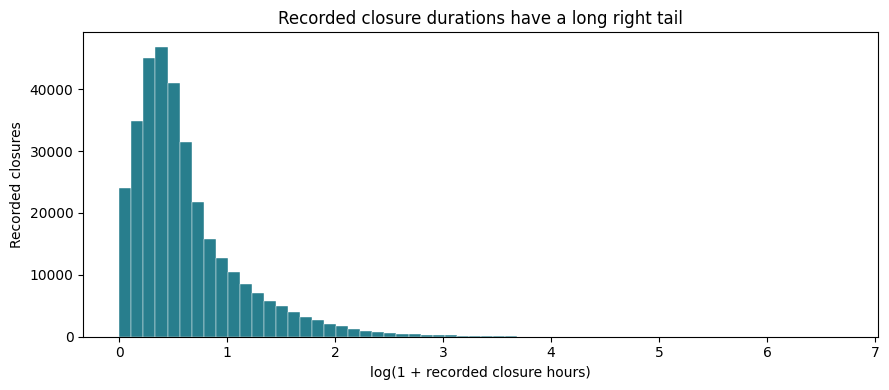

<div dir="rtl">میانگین مدت 1.24 ساعت و میانه 0.62 ساعت است؛ صدک ۹۹ به 10.06 ساعت می‌رسد. توزیع متقارن نیست و اتکا به میانگین، پروندهٔ معمول را خوب توصیف نمی‌کند.</div>

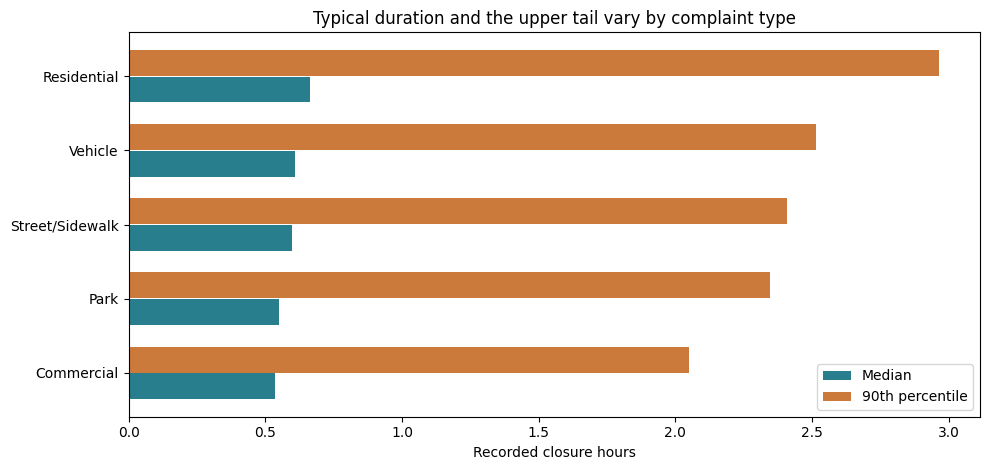

<div dir="rtl">بیشترین میانه مربوط به Noise - Residential با 0.66 ساعت و کمترین مربوط به Noise - Commercial با 0.54 ساعت است؛ یک آمار مشترک تفاوت نوع شکایت را پنهان می‌کند.</div>

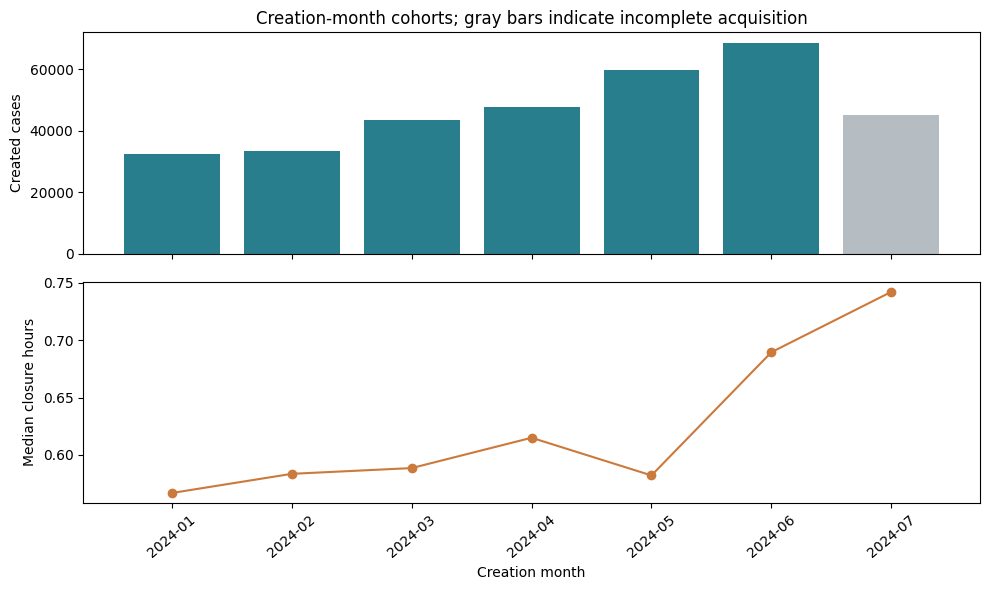

<div dir="rtl">فقط 6 ماه کامل در دسترس است. ستون خاکستری ماه ناقص را نشان می‌دهد و افت تعداد آن شاهد کاهش شکایت نیست؛ مدت‌ها نیز به فرصت پیگیری وابسته‌اند.</div>

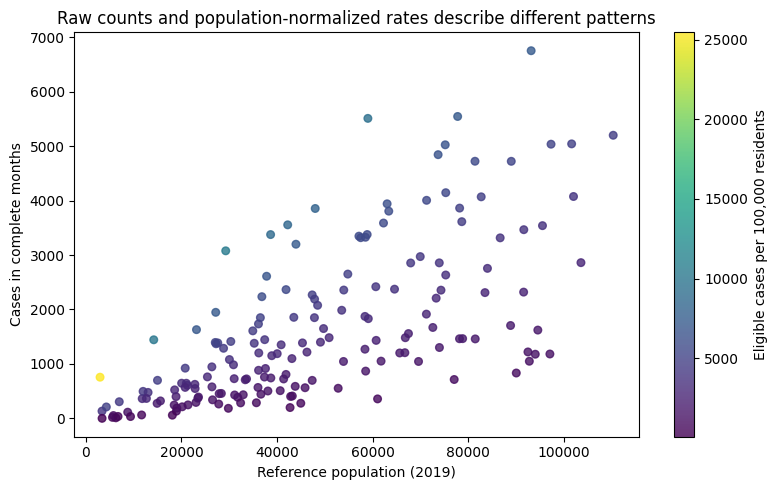

<div dir="rtl">ناحیهٔ دارای بیشترین تعداد خام MODZCTA:10456 و ناحیهٔ دارای بیشترین نرخ MODZCTA:10004 است. رتبه‌بندی برحسب حجم و برحسب جمعیت متفاوت است؛ نرخ‌ها فقط مربوط به ماه‌های کامل و مخرج تاریخی‌اند.</div>

In [25]:
figures = make_figures(cases, eda)
duration = eda["duration_description"]
complaints = eda["complaints"].dropna(subset=["median_hours"])
area = eda["area"]
claims = {
    "duration": f"میانگین مدت {duration['mean']:.2f} ساعت و میانه {duration['50%']:.2f} ساعت است؛ صدک ۹۹ به {duration['99%']:.2f} ساعت می‌رسد. توزیع متقارن نیست و اتکا به میانگین، پروندهٔ معمول را خوب توصیف نمی‌کند.",
    "complaint": f"بیشترین میانه مربوط به {complaints['median_hours'].idxmax()} با {complaints['median_hours'].max():.2f} ساعت و کمترین مربوط به {complaints['median_hours'].idxmin()} با {complaints['median_hours'].min():.2f} ساعت است؛ یک آمار مشترک تفاوت نوع شکایت را پنهان می‌کند.",
    "monthly": f"فقط {len(eda['complete_months'])} ماه کامل در دسترس است. ستون خاکستری ماه ناقص را نشان می‌دهد و افت تعداد آن شاهد کاهش شکایت نیست؛ مدت‌ها نیز به فرصت پیگیری وابسته‌اند.",
    "population": "تعداد خام و نرخ از دو سؤال متفاوت پشتیبانی می‌کنند؛ جمعیت ۲۰۱۹ و حذف موارد نامعتبر فقط از صورت نرخ، باید هنگام مقایسه دیده شوند.",
}
if not area.empty:
    count_top = area['case_count_complete_months'].idxmax()
    rate_top = area['rate_per_100k_complete_months'].idxmax()
    claims['population'] = f"ناحیهٔ دارای بیشترین تعداد خام {count_top} و ناحیهٔ دارای بیشترین نرخ {rate_top} است. رتبه‌بندی برحسب حجم و برحسب جمعیت {'متفاوت است' if count_top != rate_top else 'در رتبهٔ اول یکسان است'}؛ نرخ‌ها فقط مربوط به ماه‌های کامل و مخرج تاریخی‌اند."
for name, figure in figures.items():
    display(figure)
    plt.close(figure)
    display(Markdown('<div dir="rtl">' + claims[name] + '</div>'))


<div dir="rtl">

### یافته‌های قابل ردیابی

یافته‌های زیر از خروجی همین اجرا ساخته می‌شوند. این‌ها توصیف snapshot هستند و دربارهٔ حل واقعی مشکل یا اثر علّی نوع شکایت ادعا نمی‌کنند.

</div>


In [26]:
findings = [claims["duration"], claims["complaint"], claims["population"],
            f"تعداد {eda['outliers']['missing_closure_records']:,} پرونده پایان ثبت‌شده ندارند و {eda['outliers']['zero_duration_records']:,} پرونده مدت صفر معتبر دارند؛ جایگزینی مقدار خالی با صفر، توزیع را تغییر می‌دهد."]
for index, finding in enumerate(findings, 1):
    display(Markdown(f'<div dir="rtl">{index}. {finding}</div>'))


<div dir="rtl">1. میانگین مدت 1.24 ساعت و میانه 0.62 ساعت است؛ صدک ۹۹ به 10.06 ساعت می‌رسد. توزیع متقارن نیست و اتکا به میانگین، پروندهٔ معمول را خوب توصیف نمی‌کند.</div>

<div dir="rtl">2. بیشترین میانه مربوط به Noise - Residential با 0.66 ساعت و کمترین مربوط به Noise - Commercial با 0.54 ساعت است؛ یک آمار مشترک تفاوت نوع شکایت را پنهان می‌کند.</div>

<div dir="rtl">3. ناحیهٔ دارای بیشترین تعداد خام MODZCTA:10456 و ناحیهٔ دارای بیشترین نرخ MODZCTA:10004 است. رتبه‌بندی برحسب حجم و برحسب جمعیت متفاوت است؛ نرخ‌ها فقط مربوط به ماه‌های کامل و مخرج تاریخی‌اند.</div>

<div dir="rtl">4. تعداد 1 پرونده پایان ثبت‌شده ندارند و 0 پرونده مدت صفر معتبر دارند؛ جایگزینی مقدار خالی با صفر، توزیع را تغییر می‌دهد.</div>

<div dir="rtl">

## وضعیت تحویل

پاس‌شدن پردازش، پوشش کامل بازه و شواهد Git جداگانه کنترل می‌شوند. فایل‌های خام و مرجع در Git نیستند؛ دادهٔ محلی باید کنار checkpoint باقی بماند. گزارش تصمیم‌ها در `report.docx` و دستور اجرای کوتاه در README قرار دارد.

</div>


In [27]:
import subprocess

git_count = subprocess.run(["git", "rev-list", "--count", "HEAD"], capture_output=True, text=True, check=True)
submission_status = {
    "offline_tests_passed": test_result.wasSuccessful(), "test_count": test_result.testsRun,
    "raw_records": delivery_report["raw_records"], "minimum_records": minimum_records,
    "minimum_volume_met": delivery_report["raw_records"] >= minimum_records,
    "full_18_month_scope_acquired": delivery_report["delivery_complete"],
    "observed_created_min": delivery_report["observed_created_min"],
    "observed_created_max": delivery_report["observed_created_max"],
    "analytical_hashes_reproduced": first_hashes == repeat_hashes,
    "git_commits": int(git_count.stdout),
    "remaining_external_requirements": ["Complete source acquisition if scope is partial", "Document a merged feature Pull Request"],
}
display(pd.Series(submission_status, name="submission_status"))
Path("data/curated_data/submission_status.json").write_text(
    json.dumps(submission_status, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
Path("data/curated_data/eda_findings.json").write_text(
    json.dumps({"findings": findings, "outliers": eda["outliers"]}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


offline_tests_passed                                                            True
test_count                                                                       148
raw_records                                                                   330000
minimum_records                                                               300000
minimum_volume_met                                                              True
full_18_month_scope_acquired                                                   False
observed_created_min                                             2024-01-01T00:00:20
observed_created_max                                             2024-07-25T23:32:51
analytical_hashes_reproduced                                                    True
git_commits                                                                       18
remaining_external_requirements    [Complete source acquisition if scope is parti...
Name: submission_status, dtype: object

1005

In [10]:
main_df = pd.read_json(
    "data/curated_data/delivery/"
    "02fc160e6673cfd7f52b2ded9cb48057eec9f46af139add0bd0cba015bdbccef/"
    "analytical_cases.jsonl",
    lines=True
)

display(main_df.head())
print(main_df.shape)

,agency,agency_name,analysis_area_key,borough,borough_comparison,city,closed_date,closure_days,closure_hours,complaint_type,...,population_rate_eligible,population_reference_date,quality_flags,reference_borough,reference_neighborhood,reference_population,resolution_action_updated_date,resolution_description,status,unique_key
0,NYPD,New York City Police Department,MODZCTA:10468,BRONX,match,BRONX,2024-01-01T00:59:31.000000,0.041100,0.986389,Noise - Residential,...,True,2019-07-01,[],BRONX,Fordham/Kingsbridge/University Heights,77811.41,2024-01-01T00:59:34.000000,The Police Department responded to the complai...,Closed,59889016
1,NYPD,New York City Police Department,MODZCTA:11207,BROOKLYN,match,BROOKLYN,2024-01-01T00:56:45.000000,0.038912,0.933889,Noise - Residential,...,True,2019-07-01,[],BROOKLYN,Cypress Hills/East New York,89031.83,2024-01-01T00:56:50.000000,The Police Department responded to the complai...,Closed,59888940
2,NYPD,New York City Police Department,MODZCTA:11377,QUEENS,match,WOODSIDE,2024-01-01T00:48:34.000000,0.033171,0.796111,Noise - Street/Sidewalk,...,True,2019-07-01,[],QUEENS,Woodside,84048.11,2024-01-01T00:48:39.000000,The Police Department responded to the complai...,Closed,59892651
3,NYPD,New York City Police Department,MODZCTA:11416,QUEENS,match,OZONE PARK,2024-01-01T00:29:32.000000,0.019919,0.478056,Noise - Street/Sidewalk,...,True,2019-07-01,[],QUEENS,Ozone Park,26389.62,2024-01-01T00:29:34.000000,The Police Department responded to the complai...,Closed,59889054
4,NYPD,New York City Police Department,MODZCTA:11434,QUEENS,match,JAMAICA,2024-01-01T01:32:22.000000,0.063437,1.522500,Noise - Street/Sidewalk,...,True,2019-07-01,[],QUEENS,Airport/South Jamaica/Springfield Gardens/St. ...,66763.37,2024-01-01T01:32:26.000000,The Police Department responded to the complai...,Closed,59892073


(330000, 32)
